In [1]:
import jax
import jax.numpy as jnp

from hcnn.constraint.constraint_state_outside_sphere import ConstraintStateOutsideSphere
from hcnn.environment import Environment
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

center = jnp.array([1, 1])
radius = 1.25

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
system = SystemLinear.factory(state_matrix, input_matrix)
policy = PolicyLQR.factory(system, state_cost, input_cost)
constraint = ConstraintStateOutsideSphere.factory(center=center, radius=radius)
environment = Environment.factory(system, policy, constraint)

In [2]:
policy

PolicyLQR(state_cost=Array([[1., 0.],
       [0., 1.]], dtype=float32), input_cost=Array([[1.]], dtype=float32), riccati_matrix=Array([[ 3.1301594, -0.6101485],
       [-0.6101485,  1.7578782]], dtype=float32), gain_matrix=Array([[ 0.61014867, -0.75787866]], dtype=float32))

In [3]:
view_range = 2.0
samples_per_axis = 15
axis_samples = jnp.linspace(-view_range, view_range, samples_per_axis)
X, Y = jnp.meshgrid(axis_samples, axis_samples, indexing="xy")
states = jnp.stack((X.flatten(), Y.flatten()), axis=-1)
next_states = jax.vmap(environment.step, in_axes=(0))(states)
difference = next_states - states
unit_difference = difference / jnp.linalg.norm(difference, axis=-1, keepdims=True)

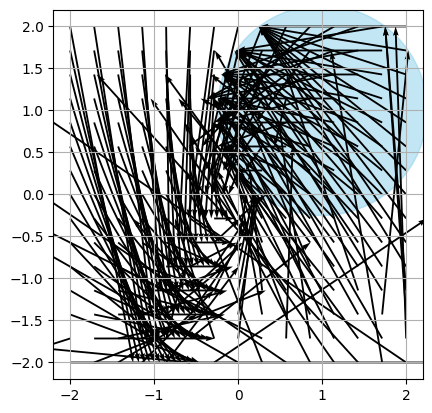

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()
ax.set_aspect("equal")
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
plt.quiver(
    states[:, 0],
    states[:, 1],
    difference[:, 0],
    difference[:, 1],
    angles="xy",
    scale_units="xy",
    scale=1,
    color="black",
    width=0.005,
)
plt.grid(True)
plt.show()

In [5]:
from hcnn.optimization.problem_policy_deviation import ProblemPolicyDeviation
from hcnn.optimization.solver_linearize import SolverLinearize

problem = ProblemPolicyDeviation.factory(
    system=system,
    policy=policy,
    constraint=constraint,
    horizon=5,
    rho=200,
).copy_with(initial_state=jnp.array([1.0, -1.0]))

problem.pretty_print(problem.x0)
print("cost", problem.cost_fun(problem.x0))
# print("lb", jnp.all(problem.lower_bound - 1e-6 <= problem.constraints(problem.x0)))
# print("ub", jnp.all(problem.constraints(problem.x0) <= problem.upper_bound + 1e-6))

actions [[-1.3680273 ]
 [ 0.37228137]
 [ 0.476363  ]
 [ 0.09557348]
 [-0.0780782 ]]
policy_actions [[-1.3680273 ]
 [ 0.37228137]
 [ 0.476363  ]
 [ 0.09557348]
 [-0.0780782 ]]
states [[ 1.         -1.        ]
 [ 0.6319727   1.        ]
 [ 0.00425404  0.6319727 ]
 [-0.15135562  0.00425404]
 [-0.06003619 -0.15135562]]
relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]]
abs_relaxations [[0.       ]
 [1.4270558]
 [0.4355458]
 [0.       ]
 [0.       ]]
cost 186.26016


In [6]:
x_star = SolverLinearize.solve(problem)
problem.pretty_print(x_star)
print("cost", problem.cost_fun(x_star))

actions [[-1.8982621 ]
 [ 0.9033324 ]
 [ 0.01180999]
 [-0.20248143]
 [-0.08496759]]
policy_actions [[-1.08594   ]
 [ 0.8951133 ]
 [ 0.01332266]
 [-0.20605108]
 [-0.08461854]]
states [[ 1.0129993  -0.5936755 ]
 [-0.25881276  1.0005593 ]
 [-0.3306682  -0.2607127 ]
 [-0.06380051 -0.3363618 ]
 [ 0.05402756 -0.06867361]]
relaxations [[-0.05439159]
 [-0.00955447]
 [-0.00384929]
 [-0.0010868 ]
 [-0.00120853]]
abs_relaxations [[ 7.35174694e-08]
 [-1.98967064e-13]
 [-1.06852715e-14]
 [-5.57578332e-12]
 [ 8.34111946e-12]]
cost 0.32998234


cost 0.32998234
lb False
ub False


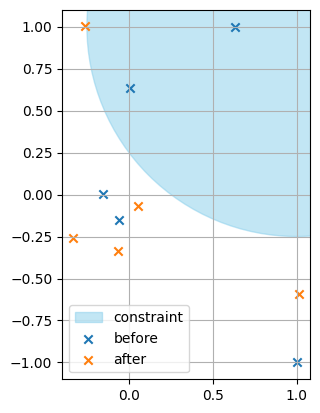

In [7]:
print("cost", problem.cost_fun(x_star))
print("lb", jnp.all(problem.lower_bound - 1e-2 <= problem.constraints(x_star)))
print("ub", jnp.all(problem.constraints(x_star) <= problem.upper_bound + 1e-2))


optvar_star = problem.debug_optvar(x_star)
optvar_0 = problem.debug_optvar(problem.x0)

# Create figure and axis
fig, ax = plt.subplots()
circle = plt.Circle(center, radius, color="skyblue", alpha=0.5, label="constraint")
ax.add_artist(circle)
plt.scatter(optvar_0.states[:, 0], optvar_0.states[:, 1], marker="x", label="before")
plt.scatter(optvar_star.states[:, 0], optvar_star.states[:, 1], marker="x", label="after")
ax.set_aspect("equal")
plt.legend()
plt.grid(True)
plt.show()